# K-means and Hierarchical Clustering in Python, Line by Line

**Unsupervised Lab · CSIT843A Lecture 4** · College of Computer Studies, University of Technology Bahrain  
Prepared by **Eng. Saeed Serwan Abdulsattar**

Interactive version with hover-to-explain code: **https://saeedserwan.github.io/unsupervised/code-clustering.html**

A complete, runnable notebook that segments 200 shop customers with K-means and hierarchical clustering. You will scale the data, choose K with the elbow and silhouette methods, read the clusters, and build a dendrogram. Hover over (or tap) any line of code to see what it does.

**You will learn to:**

1. Load and explore a customer dataset with pandas
2. Standardise features before clustering
3. Choose K with the elbow and silhouette methods
4. Fit K-means, read centroids and describe each segment
5. Build, read and cut a dendrogram with SciPy

> Run the cells from top to bottom (Shift + Enter). After each code cell, a **Line by line** note explains what every line does.

## 1. Import the libraries

We need **NumPy** for maths, **pandas** for tables, **Matplotlib** for charts, **scikit-learn** for scaling and K-means, and **SciPy** for the dendrogram.

In [1]:
%config InlineBackend.figure_format = "retina"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#ececec"
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]

**Line by line**

1. `%config InlineBackend.figure_format = "retina"`  
   A Jupyter setting (not Python): draw sharper plots on high-resolution screens.
2. `import numpy as np`  
   NumPy: fast arrays and maths. `np` is the standard nickname.
3. `import pandas as pd`  
   pandas: tables (DataFrames) with named columns.
4. `import matplotlib.pyplot as plt`  
   Matplotlib's plotting interface, used for every chart.
5. `from sklearn.preprocessing import StandardScaler`  
   Rescales each column to mean 0 and standard deviation 1.
6. `from sklearn.cluster import KMeans`  
   The K-means algorithm.
7. `from sklearn.metrics import silhouette_score, adjusted_rand_score`  
   Scores for judging a clustering and comparing two clusterings.
8. `from scipy.cluster.hierarchy import linkage, dendrogram, fcluster`  
   Hierarchical clustering: build the tree, draw it, cut it.
9. `plt.rcParams["figure.figsize"] = (7, 4.5)`  
   Default figure size (width, height) in inches.
10. `plt.rcParams["axes.spines.top"] = False` …  
   A cleaner look: hide the top and right borders of every chart.
11. `plt.rcParams["axes.grid"] = True` …  
   Light grid lines make values easier to read.
12. `COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]`  
   The same six cluster colours as the website, in a fixed order.

## 2. Load the dataset

The file records **200 customers** of a shopping mall: their age, annual income (thousands of BD) and a *spending score* from 1 to 99 that the mall gives each customer based on how much they buy.
There is **no answer column**: nobody has told us which "type" each customer is. That is what we want to discover.

In [2]:
url = "https://raw.githubusercontent.com/SaeedSerwan/unsupervised/main/data/customers.csv"
df = pd.read_csv(url)
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (200, 4)


,customer_id,age,annual_income_k,spending_score
0,1,30,18.6,74
1,2,21,28.0,19
2,3,33,83.6,81
3,4,40,82.0,13
4,5,37,19.7,73


**Line by line**

1. `url = "https://raw.githubusercontent.com/SaeedSerwan/unsupervised/main/data/customers.csv"`  
   The file's web address. You can also download the CSV and use its local file name.
2. `df = pd.read_csv(url)`  
   Read the CSV into a DataFrame. Each row is one customer.
3. `print("Rows and columns:", df.shape)`  
   `.shape` gives (rows, columns): 200 customers, 4 columns.
4. `df.head()`  
   Show the first 5 rows.

## 3. Explore the data

Always look before you cluster. Summary statistics tell us the scale of each column; a scatter plot shows whether groups are visible.

In [3]:
df.describe().round(1)

,customer_id,age,annual_income_k,spending_score
count,200.0,200.0,200.0,200.0
mean,100.5,33.7,54.8,48.3
std,57.9,9.6,27.6,28.4
min,1.0,18.0,10.8,3.0
25%,50.8,26.0,26.4,20.0
50%,100.5,33.0,54.6,50.0
75%,150.2,41.0,81.5,75.0
max,200.0,64.0,100.0,98.0


**Line by line**

1. `df.describe().round(1)`  
   Count, mean, standard deviation, min, quartiles and max for every column.

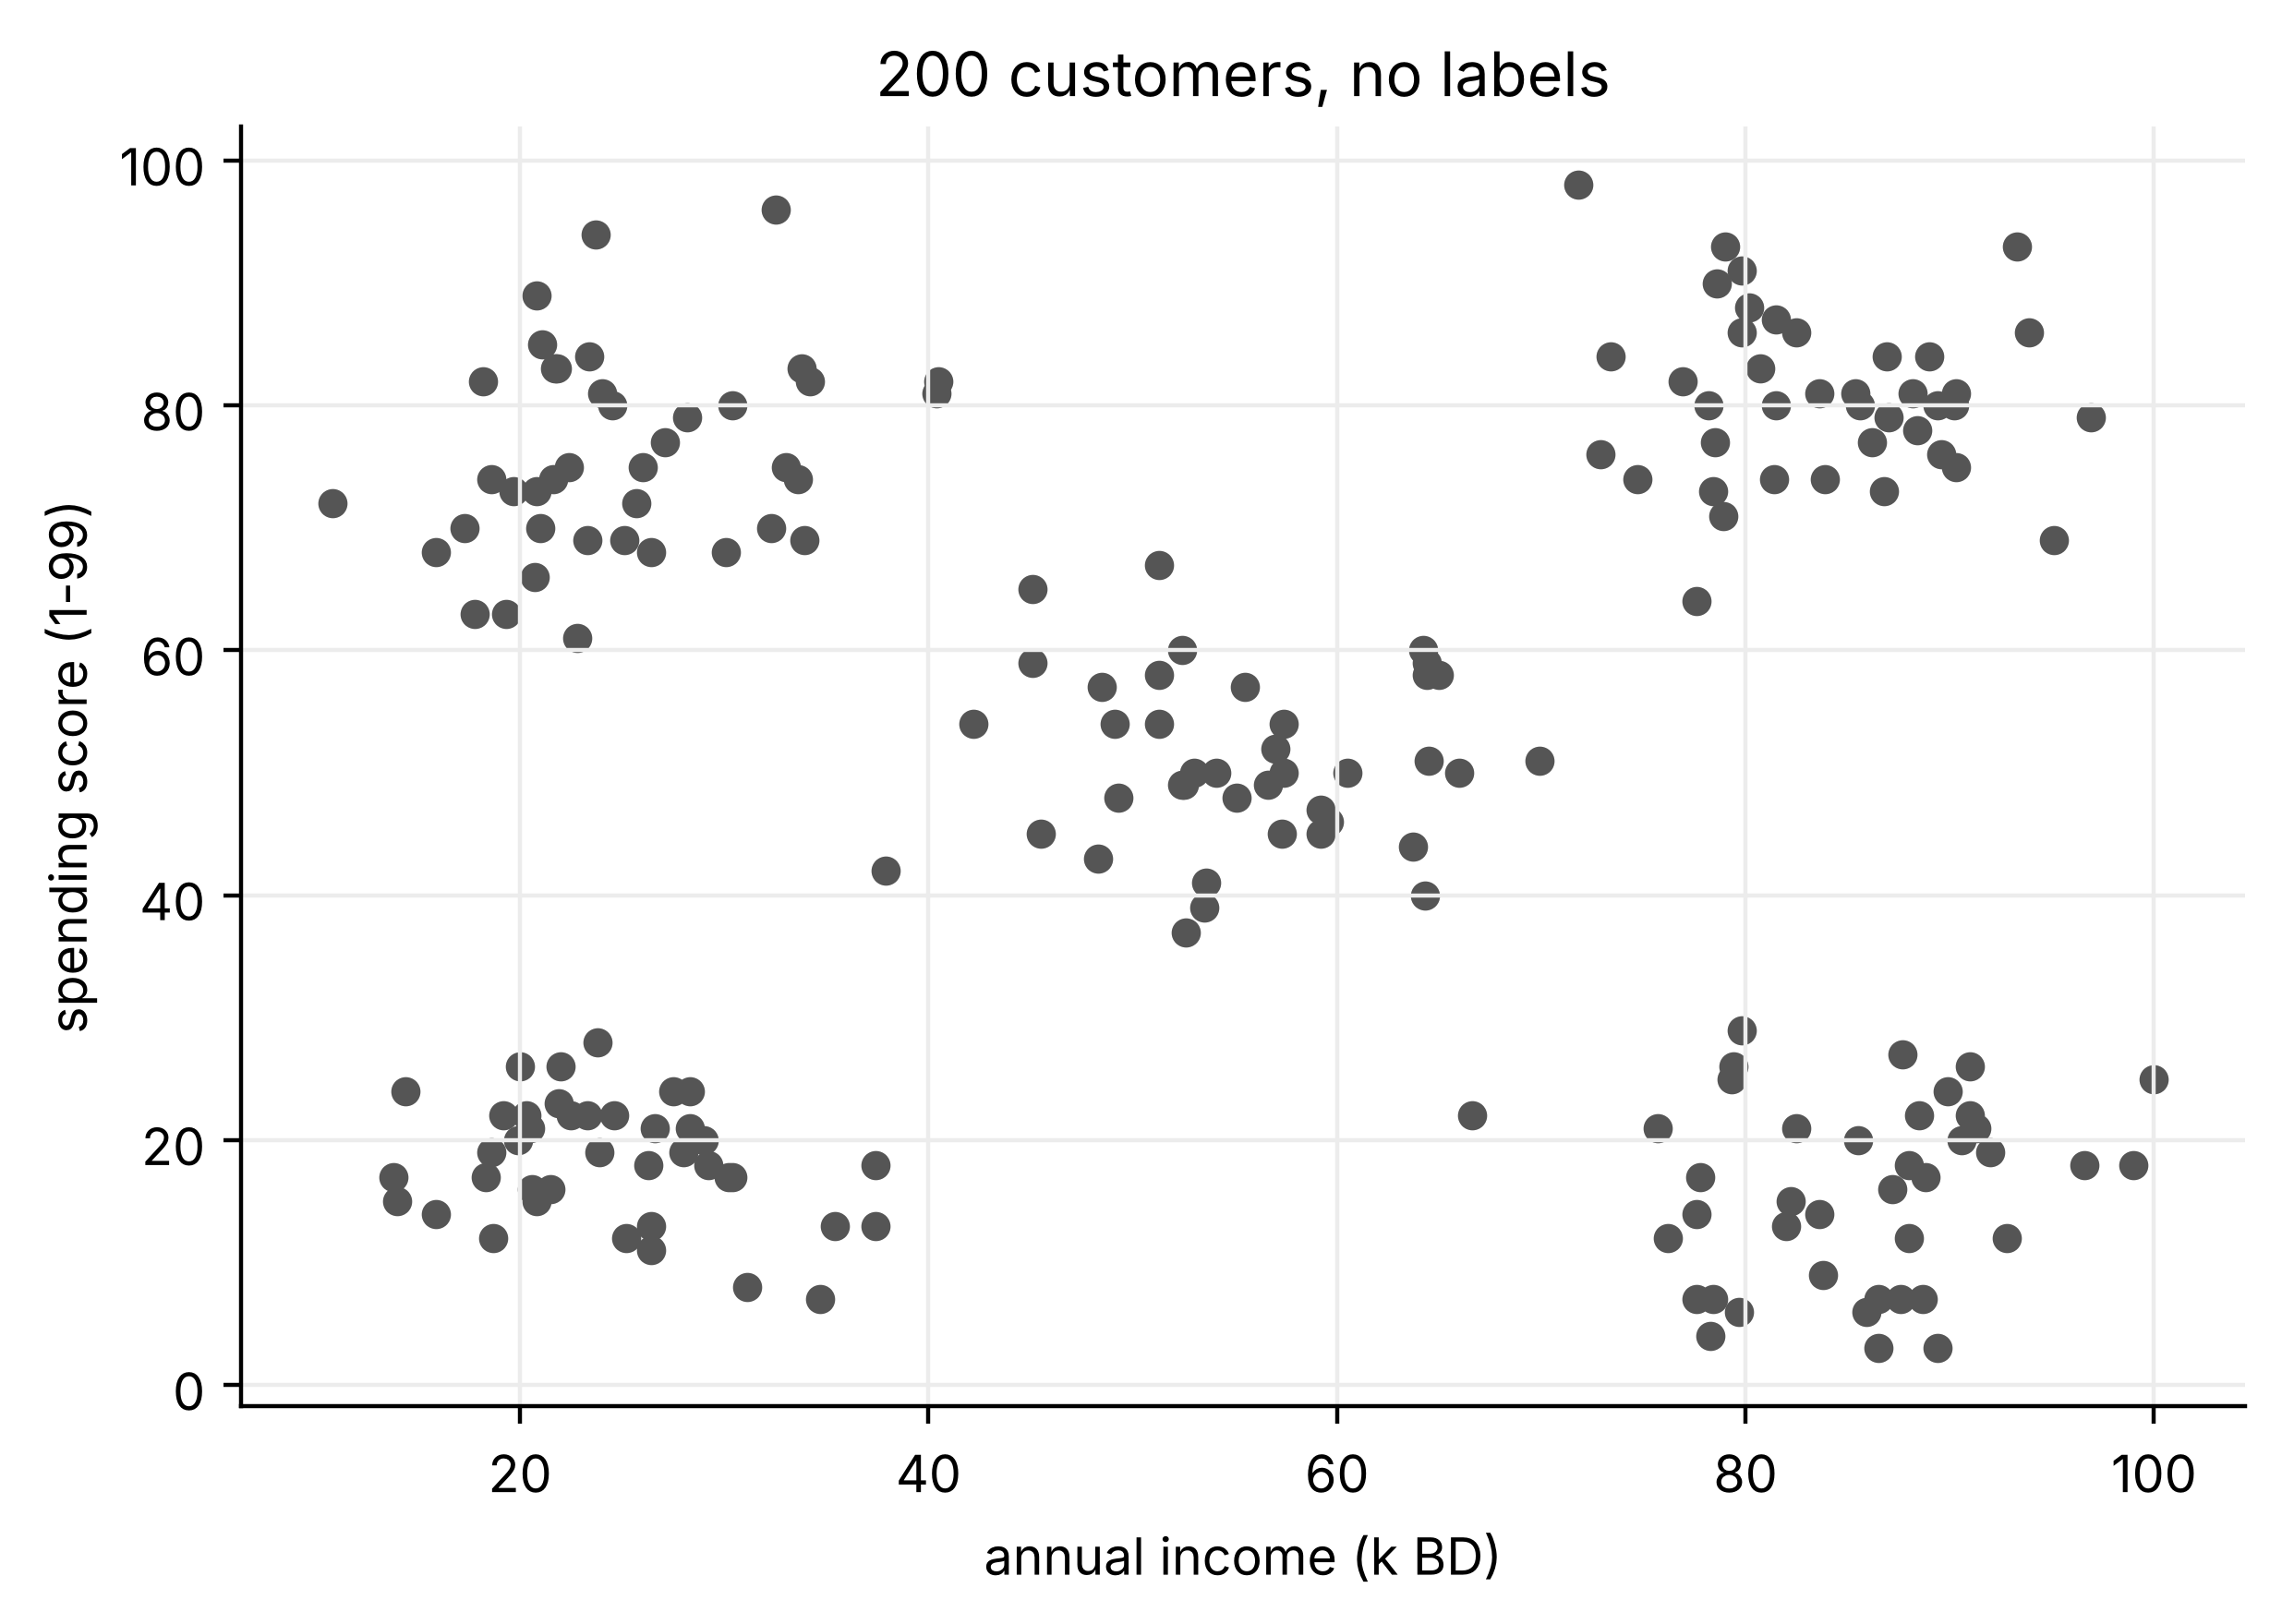

In [4]:
fig, ax = plt.subplots()
ax.scatter(df["annual_income_k"], df["spending_score"], s=22, color="#555")
ax.set(xlabel="annual income (k BD)", ylabel="spending score (1-99)",
       title="200 customers, no labels")
plt.show()

**Line by line**

1. `fig, ax = plt.subplots()`  
   One figure with one set of axes.
2. `ax.scatter(df["annual_income_k"], df["spending_score"], s=22, color="#555")`  
   One grey dot per customer: income across, spending score up.
3. `ax.set(xlabel="annual income (k BD)", ylabel="spending score (1-99)",` …  
   Label the axes and give the chart a title.
4. `plt.show()`  
   Display the figure.

Our eyes can probably see about **five** groups. Let us see whether K-means agrees, without telling it anything except the numbers.

> We cluster on **income** and **spending score** only, so every result can be drawn in 2D. With more columns the code is identical; only the plots change.

## 4. Standardise the features

K-means uses Euclidean distance, so a column with bigger numbers would get a bigger vote. `StandardScaler` subtracts each column's mean and divides by its standard deviation, so both columns count equally.

In [5]:
X = df[["annual_income_k", "spending_score"]].to_numpy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Means after scaling:", X_scaled.mean(axis=0).round(3))
print("Std after scaling:  ", X_scaled.std(axis=0).round(3))

Means after scaling: [-0. -0.]
Std after scaling:   [1. 1.]


**Line by line**

1. `X = df[["annual_income_k", "spending_score"]].to_numpy()`  
   Take the two columns we will cluster on, as a NumPy array (200 rows × 2 columns).
2. `scaler = StandardScaler()`  
   Create the scaler.
3. `X_scaled = scaler.fit_transform(X)`  
   `fit` learns each column's mean and standard deviation; `transform` applies z = (x − mean) / sd.
4. `print("Means after scaling:", X_scaled.mean(axis=0).round(3))`  
   Both columns now have mean 0 …
5. `print("Std after scaling:  ", X_scaled.std(axis=0).round(3))`  
   … and standard deviation 1.

## 5. Choose K: the elbow method

Fit K-means for K = 1 … 10 and record the **inertia**: the total squared distance of points to their own centroid (the lecture's objective, without the factor 2). It always falls as K grows, so we look for the **elbow** where it stops falling fast.

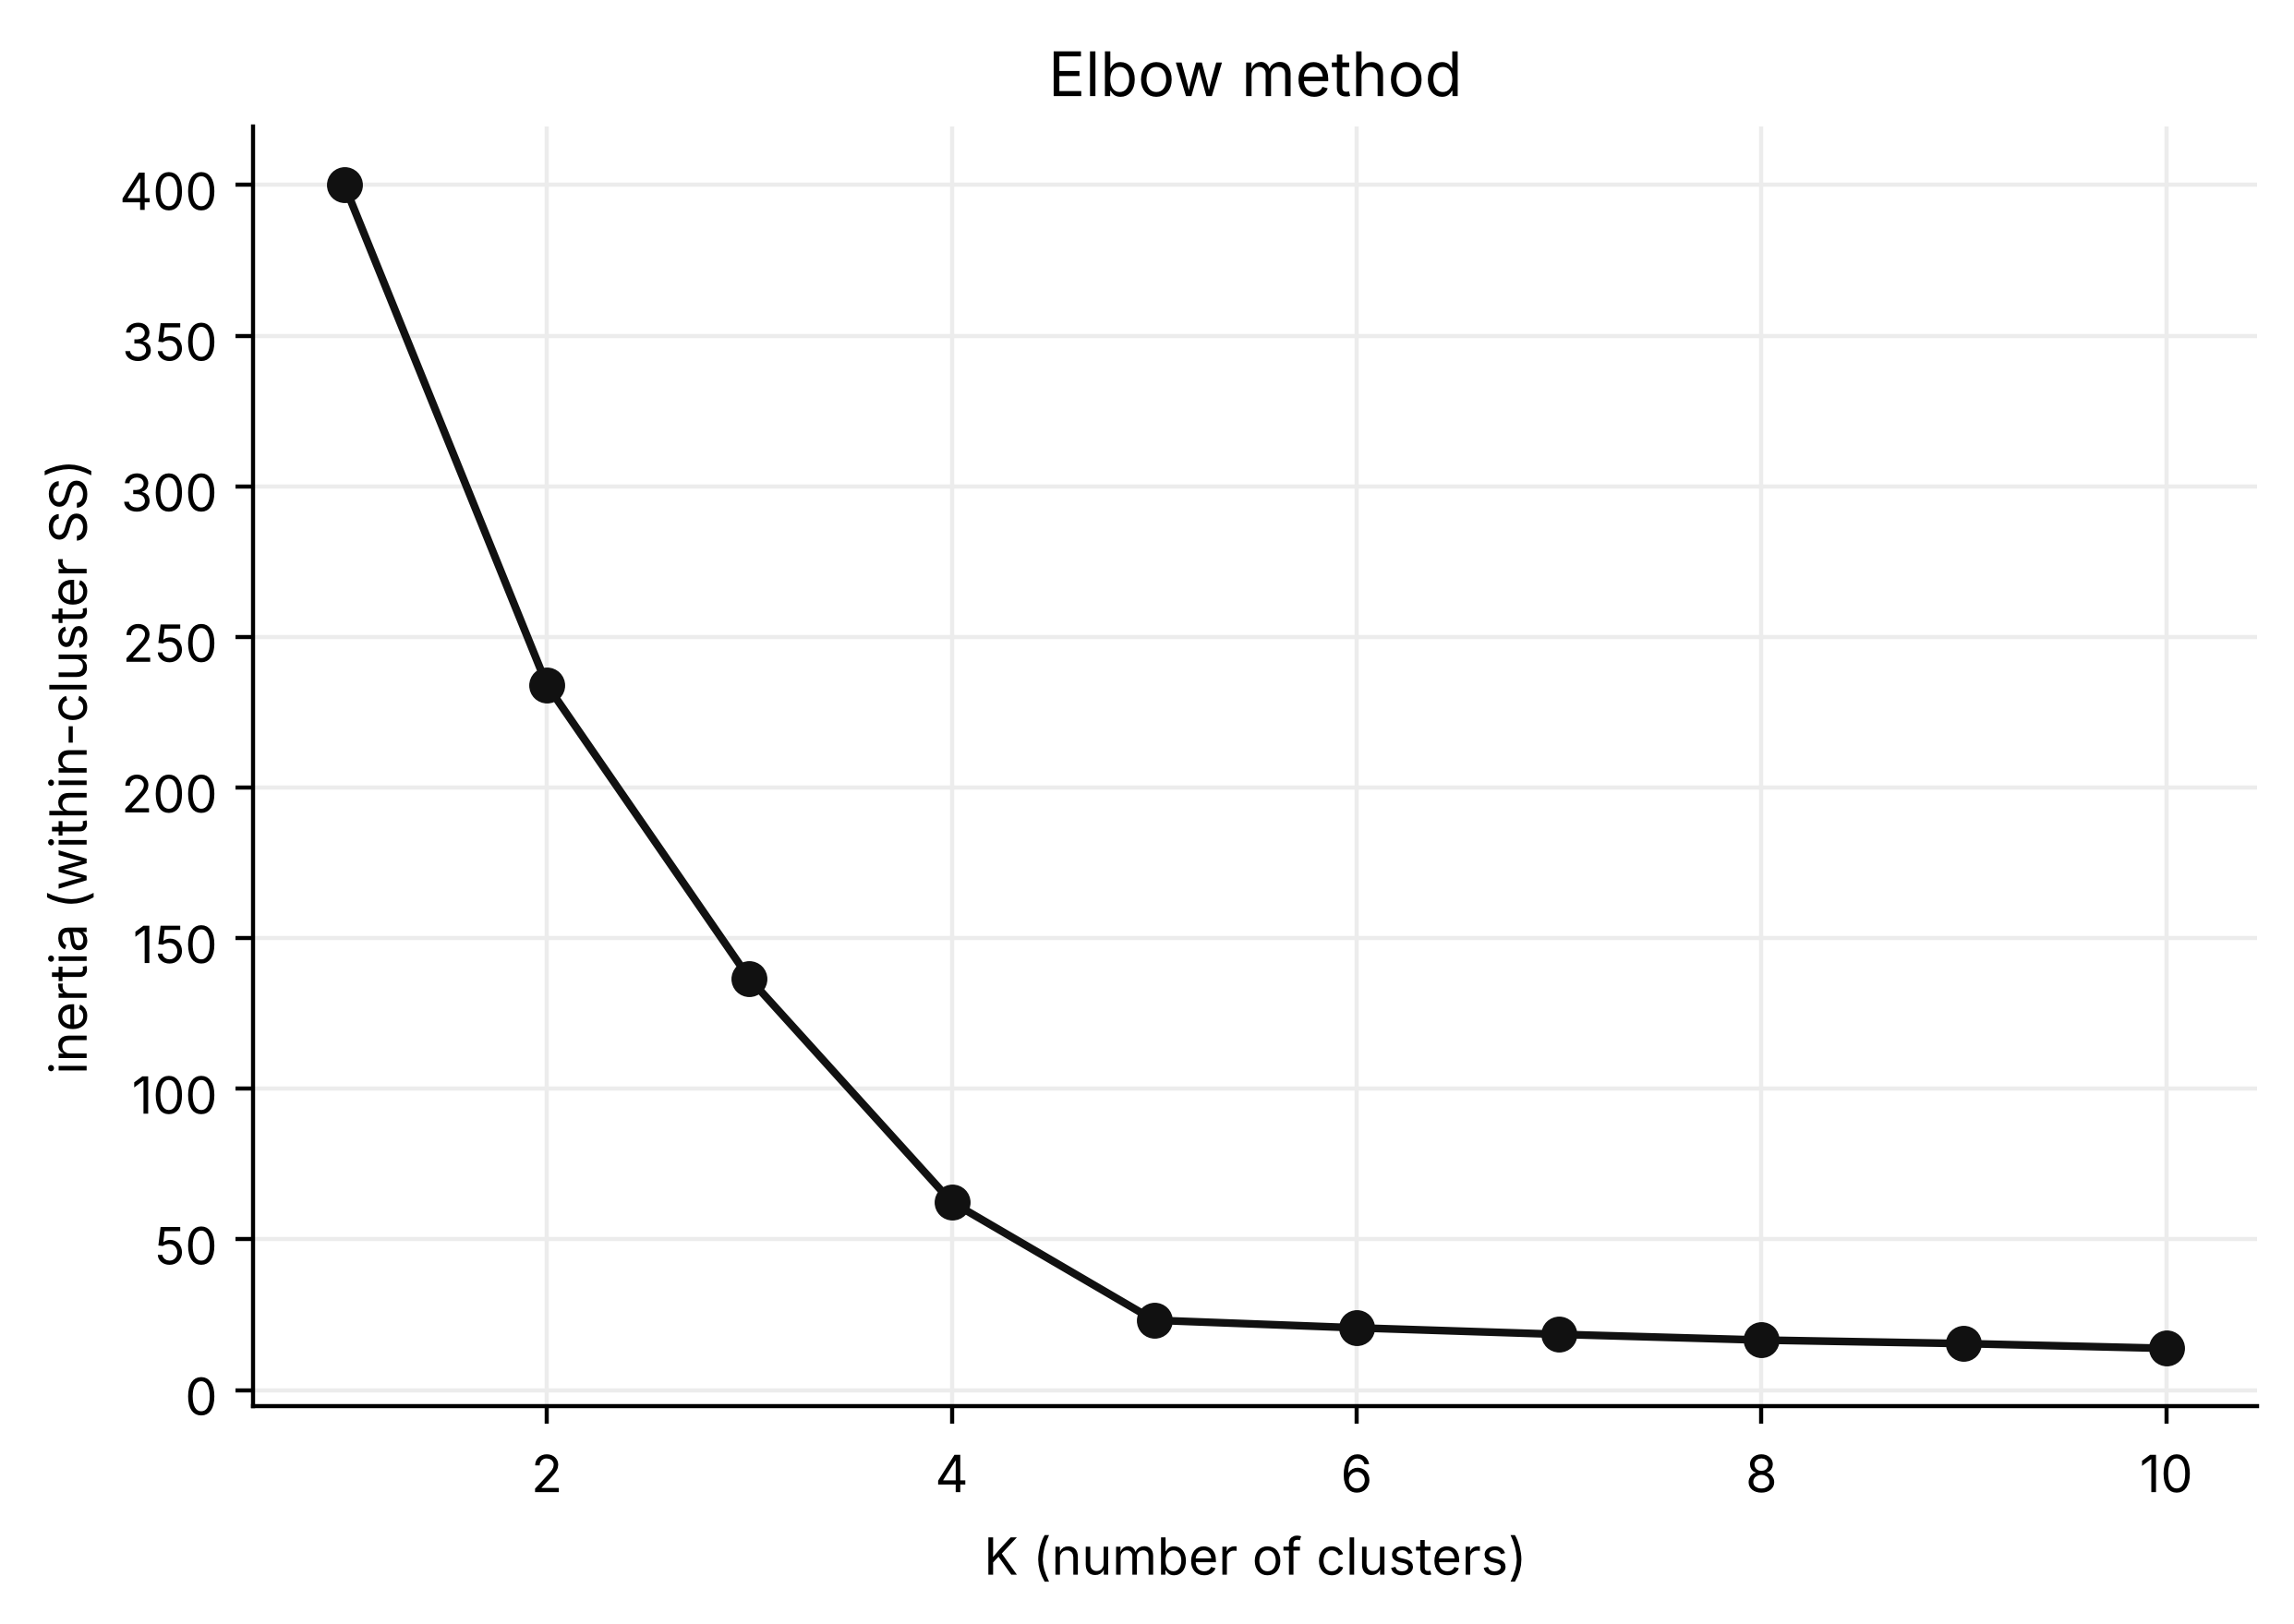

In [6]:
ks = range(1, 11)
inertias = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=0)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

fig, ax = plt.subplots()
ax.plot(ks, inertias, "o-", color="#111")
ax.set(xlabel="K (number of clusters)", ylabel="inertia (within-cluster SS)", title="Elbow method")
plt.show()

**Line by line**

1. `ks = range(1, 11)`  
   The values of K we will try: 1, 2, …, 10.
2. `inertias = []`  
   An empty list to collect one inertia per K.
3. `for k in ks:`  
   Loop over every K …
4. `km = KMeans(n_clusters=k, n_init=10, random_state=0)`  
   … create K-means with K clusters. `n_init=10` runs 10 random starts and keeps the best (lowest inertia); `random_state` makes it repeatable.
5. `km.fit(X_scaled)`  
   Run the assign / update loop until it converges.
6. `inertias.append(km.inertia_)`  
   Save the final objective for this K.
7. `fig, ax = plt.subplots()`  
   A new chart.
8. `ax.plot(ks, inertias, "o-", color="#111")`  
   Inertia against K, with a dot at each K.
9. `ax.set(xlabel="K (number of clusters)", ylabel="inertia (within-cluster SS)", title="Elbow method")`  
   Labels and title.
10. `plt.show()`  
   Display.

The curve drops steeply until **K = 5**, then flattens: adding more clusters stops paying off. That is the elbow.

## 6. Choose K: the silhouette score

For each point the silhouette compares its average distance to its own cluster ($a$) with its average distance to the nearest other cluster ($b$): $s = (b - a) / \max(a, b)$. Values near 1 mean well-separated clusters. We pick the K with the highest average.

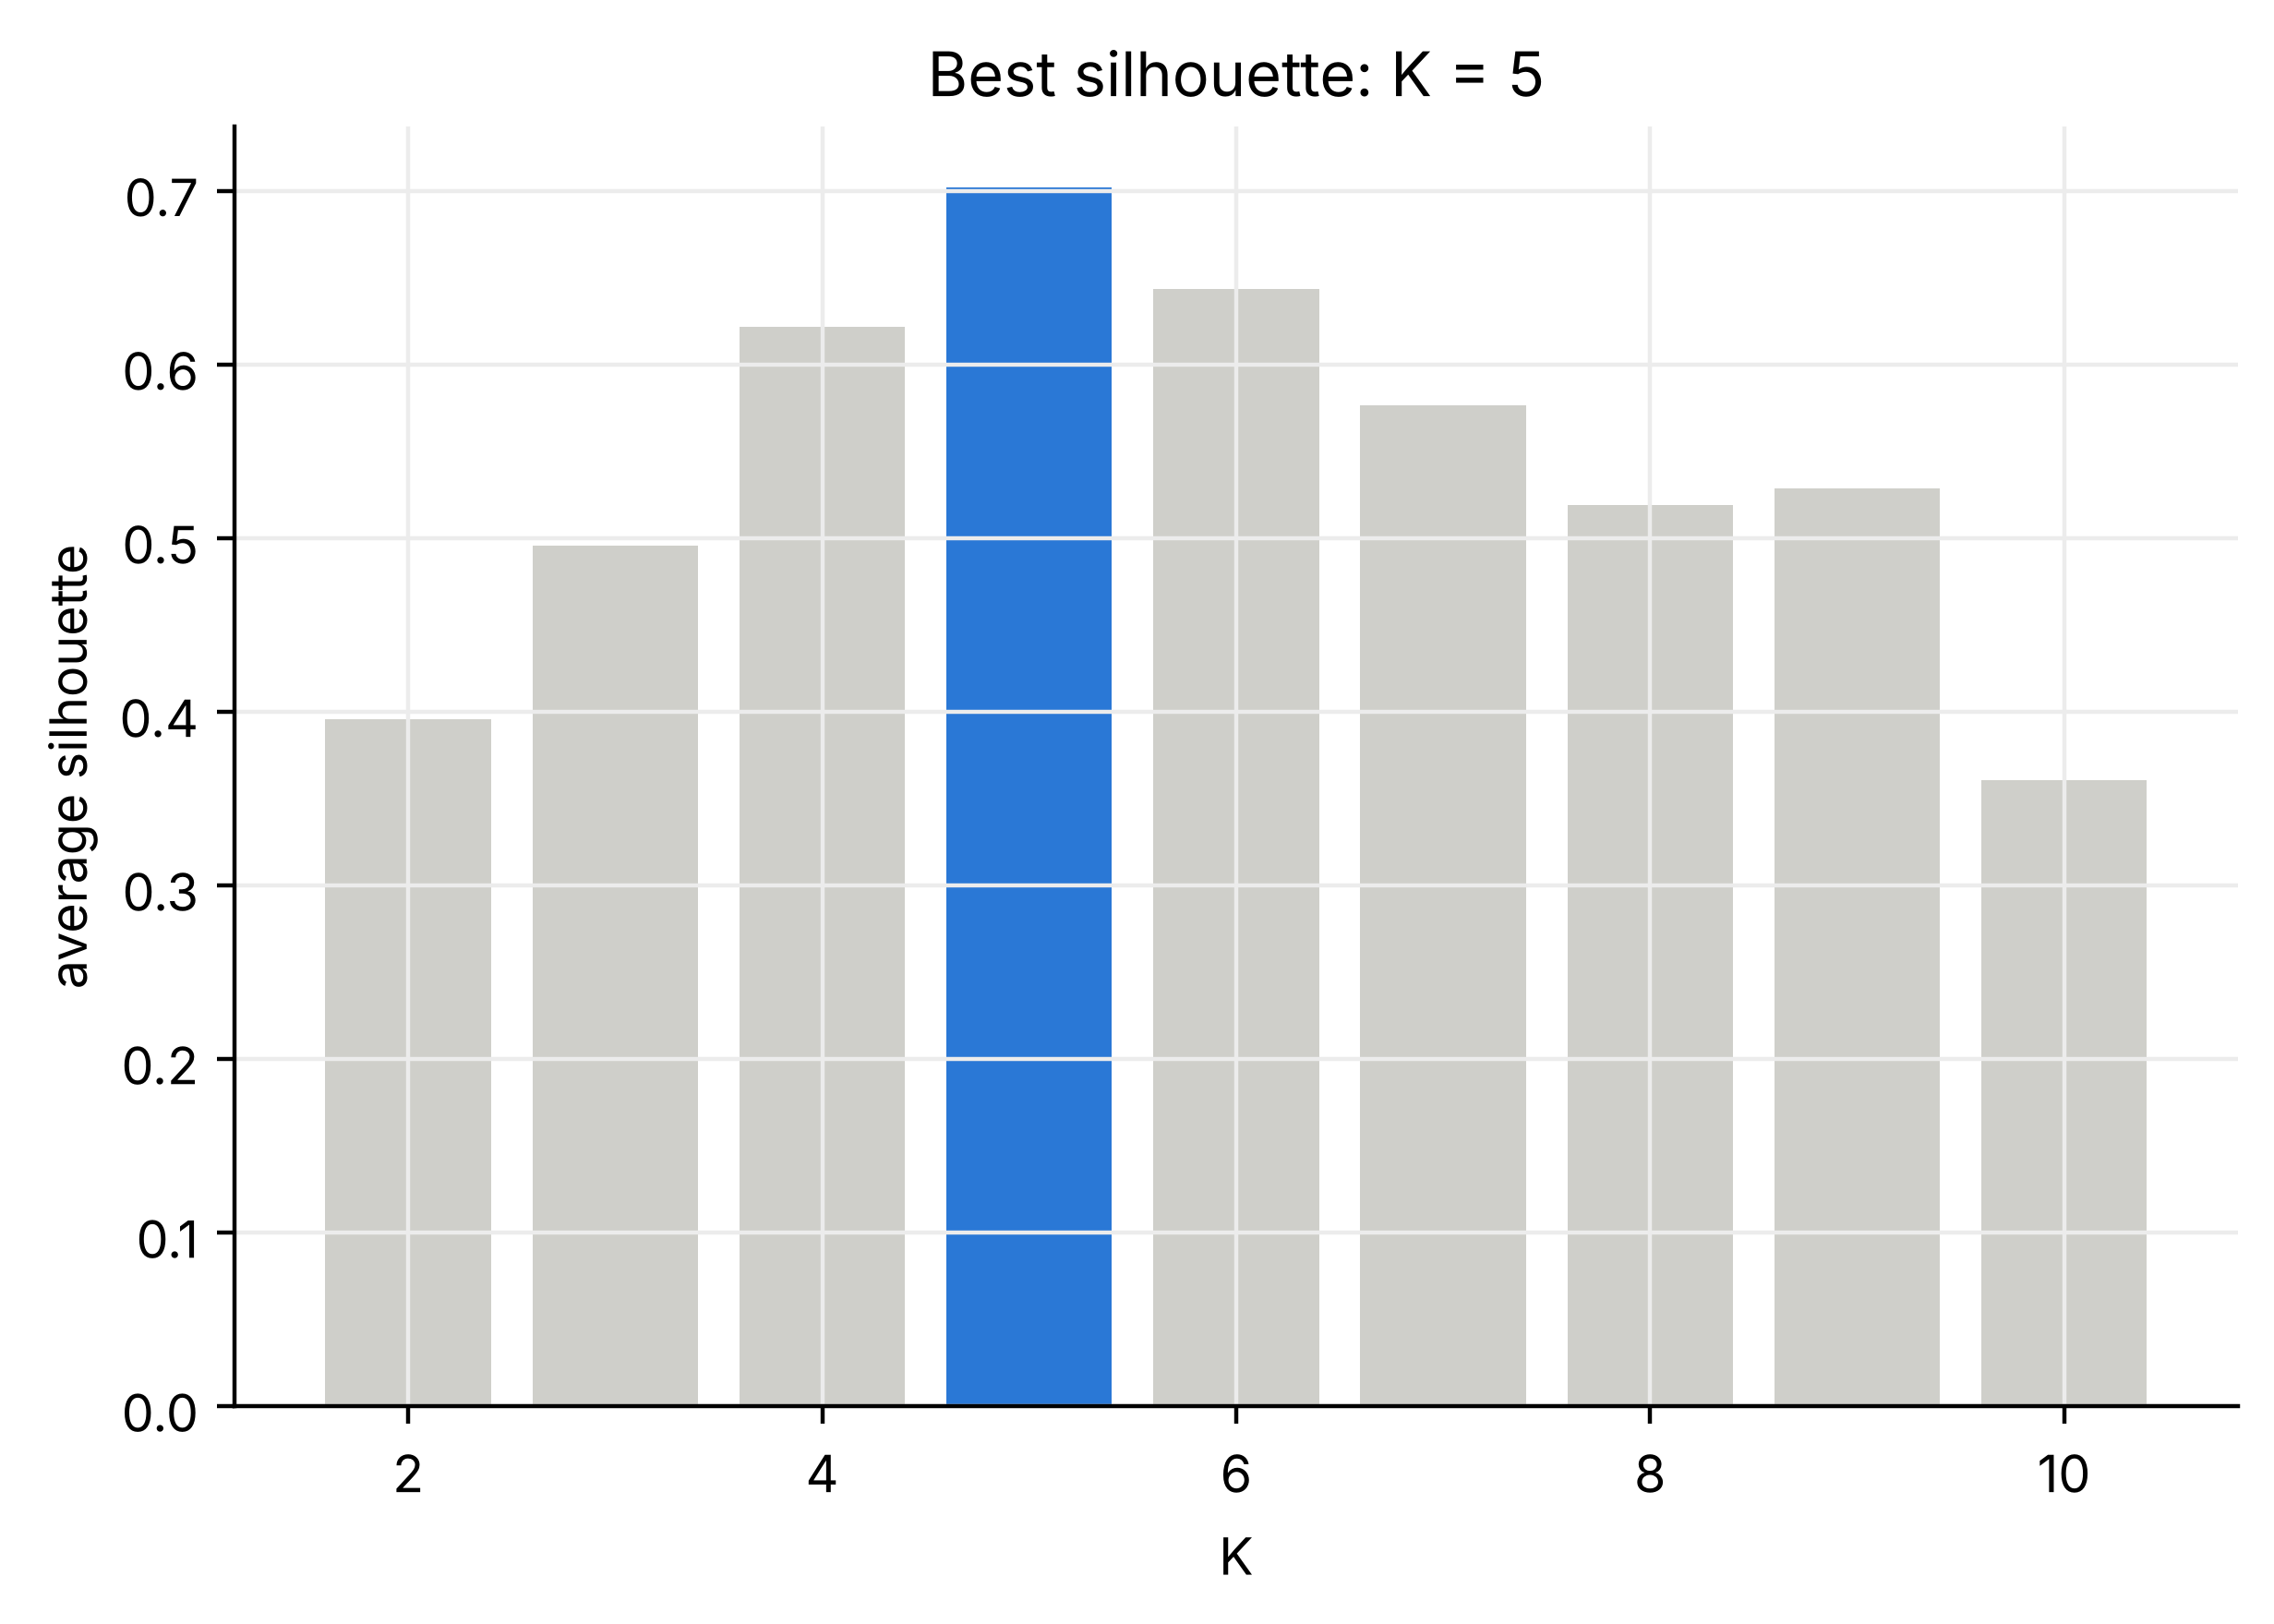

In [7]:
sil = {}
for k in range(2, 11):
    labels = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X_scaled)
    sil[k] = silhouette_score(X_scaled, labels)

best_k = max(sil, key=sil.get)
fig, ax = plt.subplots()
ax.bar(list(sil), list(sil.values()), color=["#2a78d6" if k == best_k else "#cfcfca" for k in sil])
ax.set(xlabel="K", ylabel="average silhouette", title=f"Best silhouette: K = {best_k}")
plt.show()

**Line by line**

1. `sil = {}`  
   A dictionary: K → average silhouette.
2. `for k in range(2, 11):`  
   The silhouette needs at least 2 clusters.
3. `labels = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X_scaled)`  
   Fit and return the cluster label of every customer, in one call.
4. `sil[k] = silhouette_score(X_scaled, labels)`  
   Average silhouette over all 200 customers.
5. `best_k = max(sil, key=sil.get)`  
   The K with the largest silhouette.
6. `fig, ax = plt.subplots()`  
   A new chart.
7. `ax.bar(list(sil), list(sil.values()), color=["#2a78d6" if k == best_k else "#cfcfca" for k in sil])`  
   One bar per K; the best one in blue.
8. `ax.set(xlabel="K", ylabel="average silhouette", title=f"Best silhouette: K = {best_k}")`  
   Labels, with the winner in the title.
9. `plt.show()`  
   Display.

Both methods point to **K = 5**. When two different tools agree, we can be more confident.

## 7. Fit K-means with K = 5

In [8]:
kmeans = KMeans(n_clusters=5, n_init=10, random_state=0)
df["cluster"] = kmeans.fit_predict(X_scaled)
centres = scaler.inverse_transform(kmeans.cluster_centers_)
print("Inertia:", round(kmeans.inertia_, 2))
print("Customers per cluster:", np.bincount(df["cluster"]))

Inertia: 23.19
Customers per cluster: [40 40 40 40 40]


**Line by line**

1. `kmeans = KMeans(n_clusters=5, n_init=10, random_state=0)`  
   The final model: 5 clusters, best of 10 random starts.
2. `df["cluster"] = kmeans.fit_predict(X_scaled)`  
   Fit, and store each customer's cluster (0-4) as a new column.
3. `centres = scaler.inverse_transform(kmeans.cluster_centers_)`  
   The centroids live in the scaled space; `inverse_transform` converts them back to BD and score units.
4. `print("Inertia:", round(kmeans.inertia_, 2))`  
   The objective of the best run.
5. `print("Customers per cluster:", np.bincount(df["cluster"]))`  
   `bincount` counts how many customers got each label.

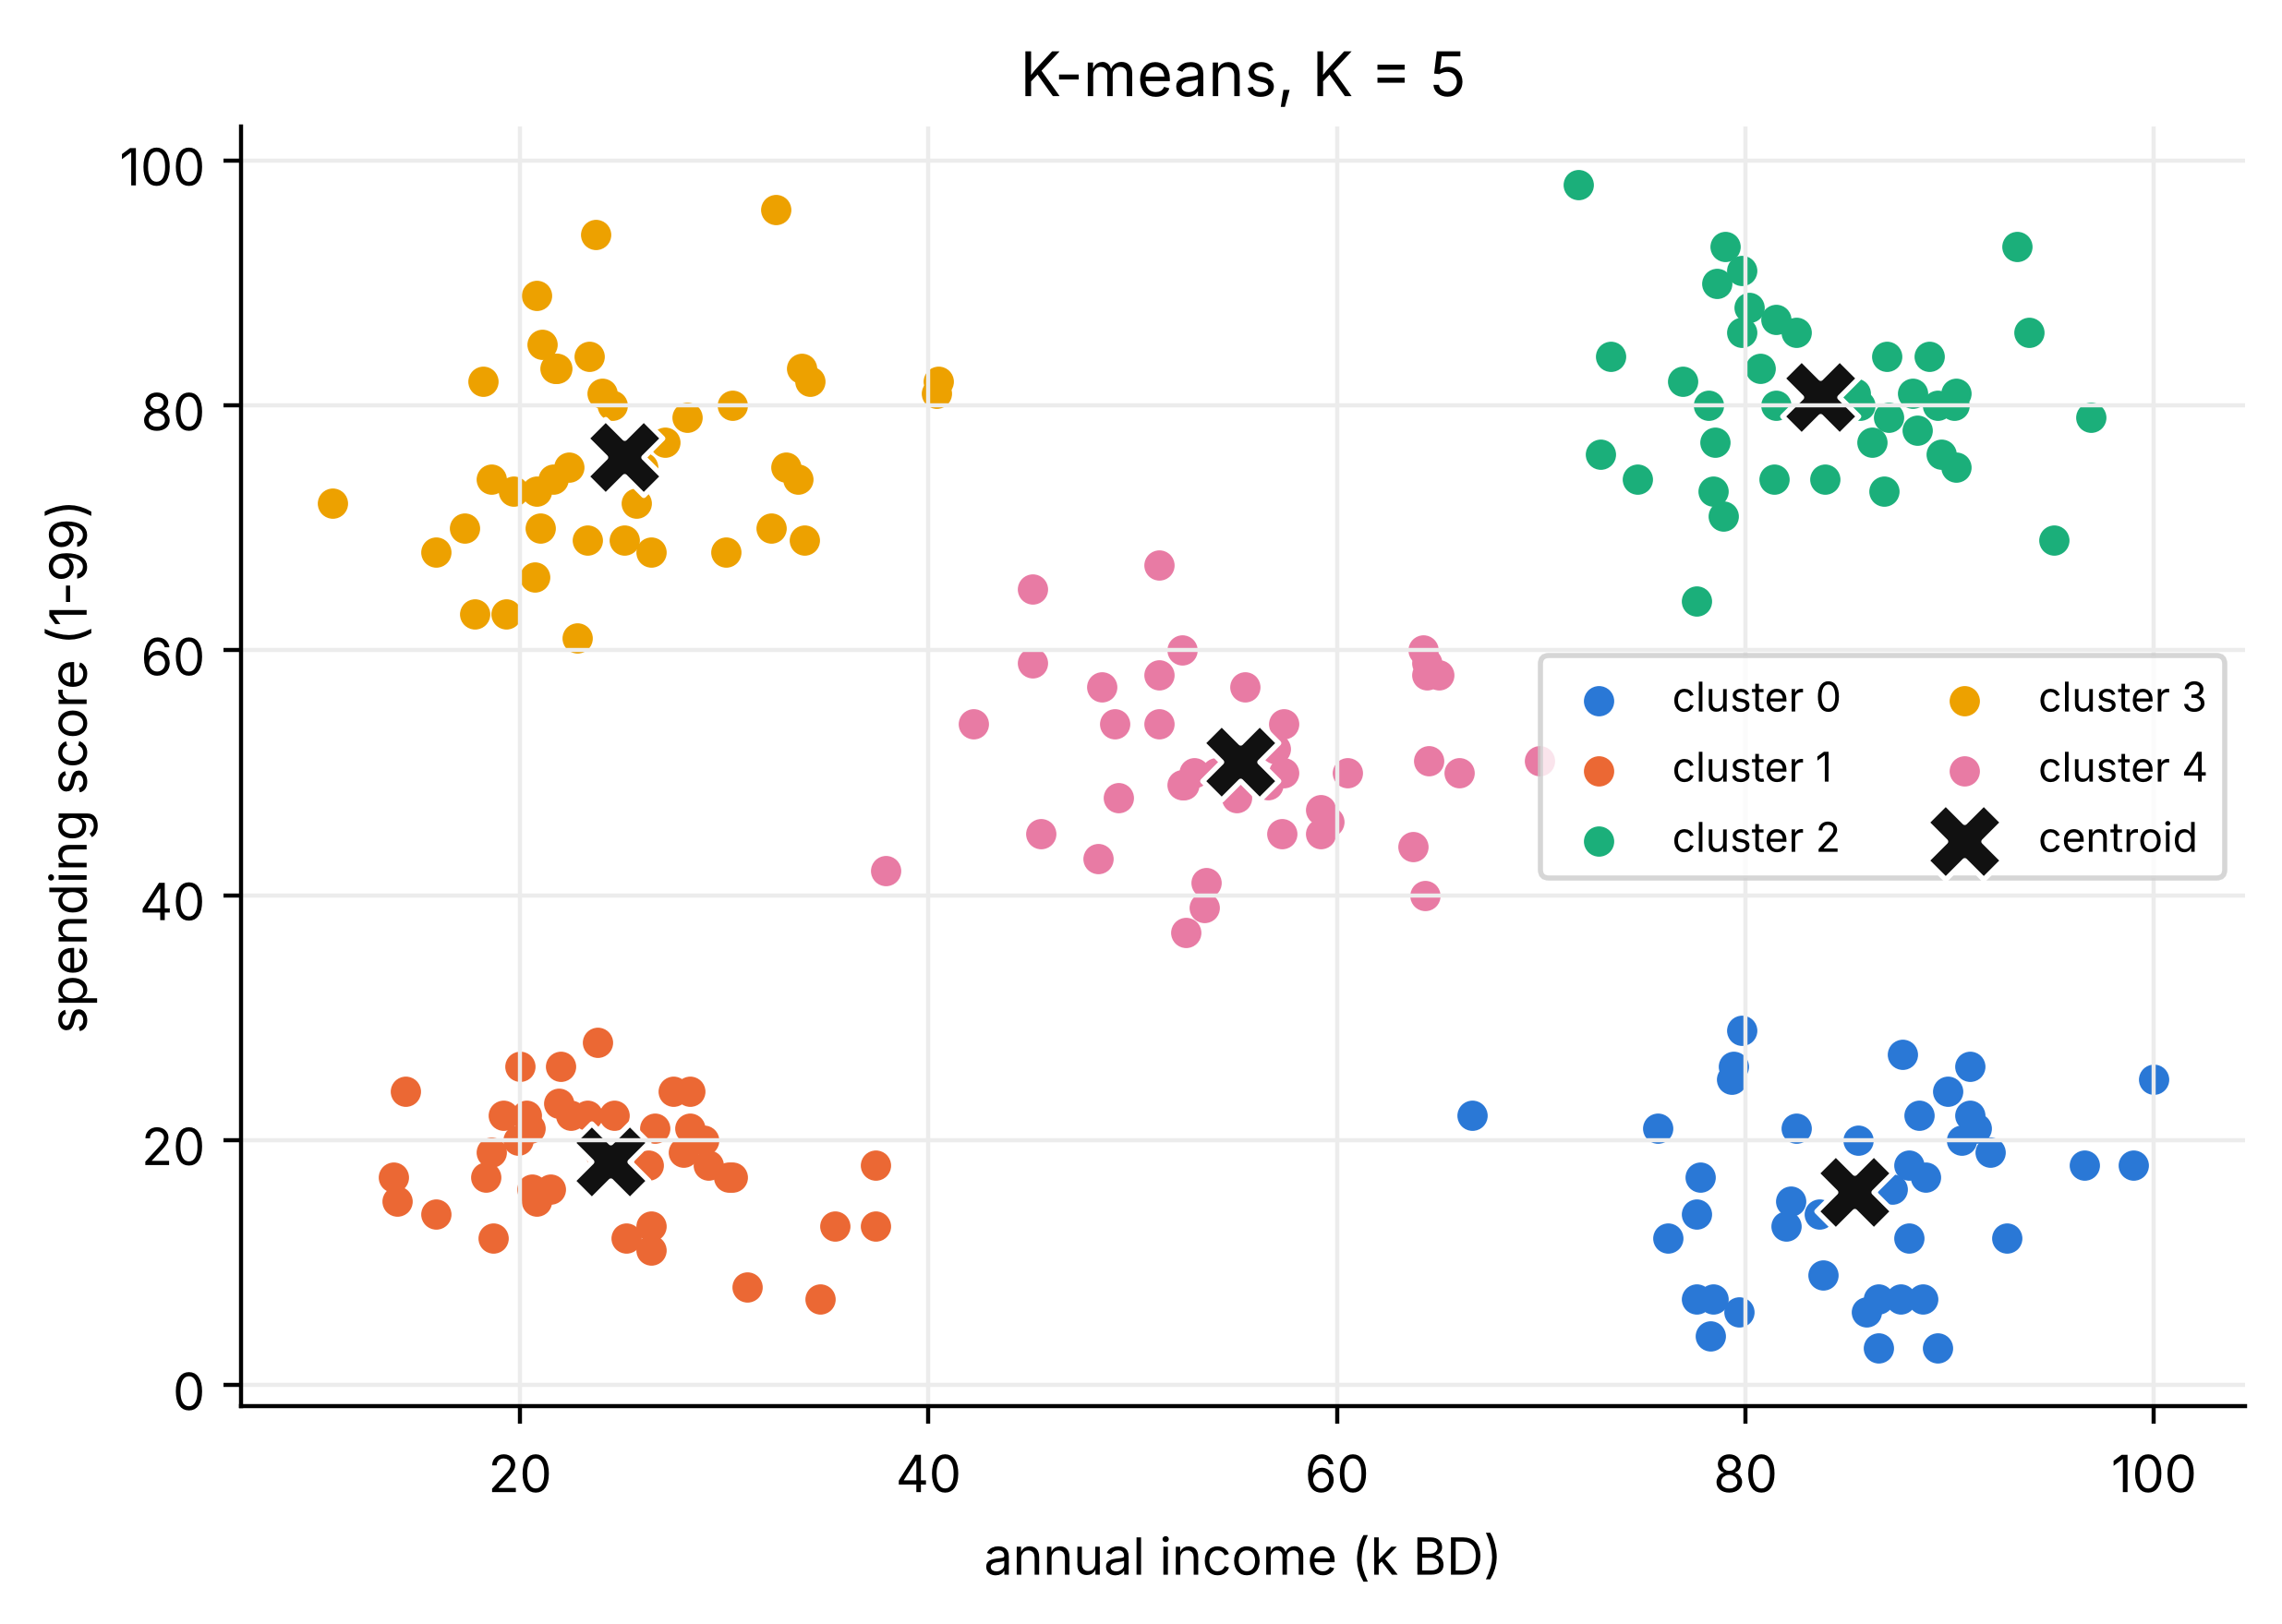

In [9]:
fig, ax = plt.subplots()
for c in range(5):
    pts = df[df["cluster"] == c]
    ax.scatter(pts["annual_income_k"], pts["spending_score"], s=24, color=COLORS[c], label=f"cluster {c}")
ax.scatter(centres[:, 0], centres[:, 1], marker="X", s=220, color="#111", edgecolor="white", label="centroid")
ax.set(xlabel="annual income (k BD)", ylabel="spending score (1-99)", title="K-means, K = 5")
ax.legend(fontsize=8, ncol=2)
plt.show()

**Line by line**

1. `fig, ax = plt.subplots()`  
   A new chart.
2. `for c in range(5):`  
   Draw one cluster at a time so each gets its own colour and legend entry.
3. `pts = df[df["cluster"] == c]`  
   The rows (customers) in cluster c.
4. `ax.scatter(pts["annual_income_k"], pts["spending_score"], s=24, color=COLORS[c], label=f"cluster {c}")`  
   Their income and spending score, in cluster c's colour.
5. `ax.scatter(centres[:, 0], centres[:, 1], marker="X", s=220, color="#111", edgecolor="white", label="centroid")`  
   The five centroids as large black crosses.
6. `ax.set(xlabel="annual income (k BD)", ylabel="spending score (1-99)", title="K-means, K = 5")`  
   Labels and title.
7. `ax.legend(fontsize=8, ncol=2)`  
   A small legend in two columns.
8. `plt.show()`  
   Display.

## 8. Describe each segment

Clusters only become useful when a human interprets them. The average of each column per cluster tells us who is in it.

In [10]:
summary = df.groupby("cluster")[["age", "annual_income_k", "spending_score"]].mean().round(1)
summary["customers"] = df["cluster"].value_counts().sort_index()
summary

,age,annual_income_k,spending_score,customers
cluster,,,,
0,41.0,85.3,15.8,40
1,28.6,24.4,18.3,40
2,30.1,83.7,80.7,40
3,26.1,25.1,75.8,40
4,42.8,55.3,50.9,40


**Line by line**

1. `summary = df.groupby("cluster")[["age", "annual_income_k", "spending_score"]].mean().round(1)`  
   Average age, income and score per cluster.
2. `summary["customers"] = df["cluster"].value_counts().sort_index()`  
   Add the size of each cluster.
3. `summary`  
   Show the table.

Reading the table, we might name them: *careful earners* (high income, low spending), *big spenders* (high income, high spending), *average customers*, *careful budgets* (low income, low spending) and *young enthusiasts* (low income, high spending). The names are **our** interpretation, not the algorithm's: K-means only says 0, 1, 2, 3, 4.

## 9. Local minima: why `n_init` matters

With a single random start, K-means can get stuck. Run it five times with `n_init=1` and compare the objective.

In [11]:
for seed in range(5):
    km = KMeans(n_clusters=5, n_init=1, init="random", random_state=seed).fit(X_scaled)
    print(f"start {seed}: inertia = {km.inertia_:.2f}")

start 0: inertia = 23.19
start 1: inertia = 23.19
start 2: inertia = 62.27
start 3: inertia = 23.19
start 4: inertia = 59.94


**Line by line**

1. `for seed in range(5):`  
   Five different random starts …
2. `km = KMeans(n_clusters=5, n_init=1, init="random", random_state=seed).fit(X_scaled)`  
   … one start each, with purely random initial centroids.
3. `print(f"start {seed}: inertia = {km.inertia_:.2f}")`  
   Print the objective each run reached.

Different starts can stop at different local minima with a worse (higher) inertia. That is why scikit-learn runs several starts and keeps the best.

## 10. Hierarchical clustering: the dendrogram

SciPy's `linkage` performs agglomerative clustering and records every merge. `dendrogram` draws the tree.

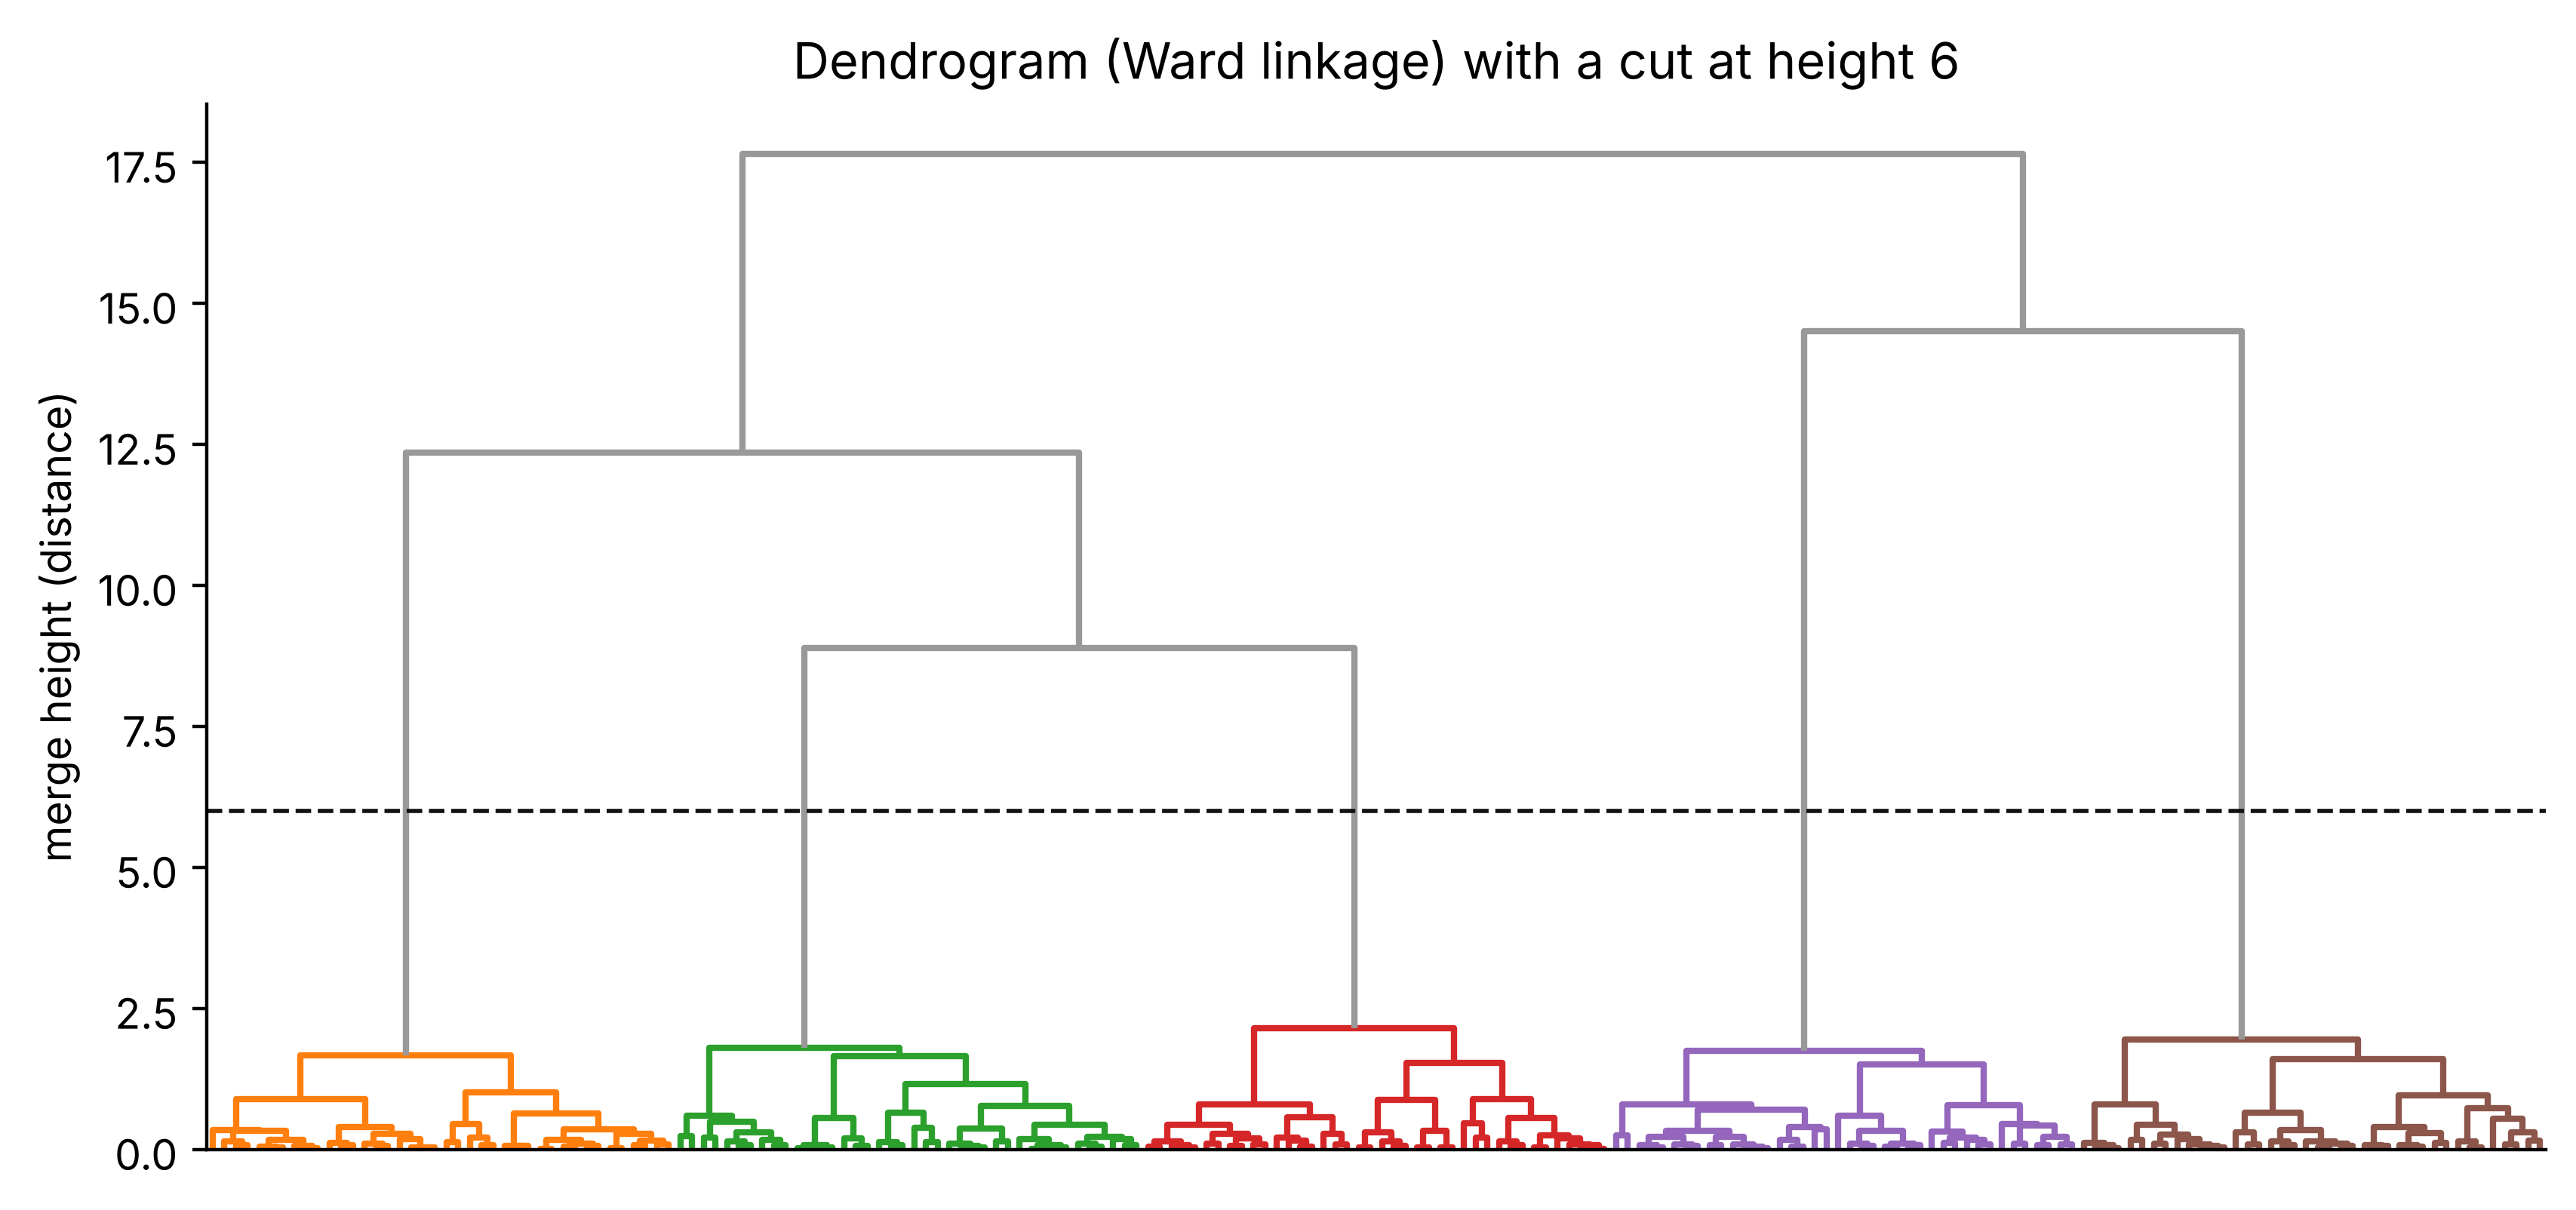

In [12]:
Z = linkage(X_scaled, method="ward")
fig, ax = plt.subplots(figsize=(10, 4.5))
dendrogram(Z, ax=ax, no_labels=True, color_threshold=6,
           above_threshold_color="#999")
ax.axhline(6, color="#111", linestyle="--", linewidth=1)
ax.set(ylabel="merge height (distance)", title="Dendrogram (Ward linkage) with a cut at height 6")
ax.grid(False)
plt.show()

**Line by line**

1. `Z = linkage(X_scaled, method="ward")`  
   Build the tree bottom-up with Ward linkage (merge the pair that increases within-cluster variation least). Try "complete", "average" or "single" too.
2. `fig, ax = plt.subplots(figsize=(10, 4.5))`  
   A wide figure: 200 leaves need space.
3. `dendrogram(Z, ax=ax, no_labels=True, color_threshold=6,` …  
   Draw the tree. Branches below height 6 are coloured by cluster; leaf labels are hidden (200 would be unreadable).
4. `ax.axhline(6, color="#111", linestyle="--", linewidth=1)`  
   The cut line at height 6.
5. `ax.set(ylabel="merge height (distance)", title="Dendrogram (Ward linkage) with a cut at height 6")`  
   Labels and title.
6. `ax.grid(False)`  
   Grid lines would clutter the tree.
7. `plt.show()`  
   Display.

Reading the tree: the long vertical gap just below the dashed line means the five groups underneath are well separated. Cutting there gives **five clusters**. Remember the rule: similarity is the **height** where branches join, not how close leaves are along the bottom.

In [13]:
df["hc"] = fcluster(Z, t=5, criterion="maxclust")
print(pd.crosstab(df["cluster"], df["hc"]))
print("Adjusted Rand index:", round(adjusted_rand_score(df["cluster"], df["hc"]), 3))

hc        1   2   3   4   5
cluster                    
0         0   0   0   0  40
1        40   0   0   0   0
2         0   0   0  40   0
3         0   0  40   0   0
4         0  40   0   0   0
Adjusted Rand index: 1.0


**Line by line**

1. `df["hc"] = fcluster(Z, t=5, criterion="maxclust")`  
   Cut the tree so that exactly 5 clusters remain; labels are 1-5.
2. `print(pd.crosstab(df["cluster"], df["hc"]))`  
   Rows: K-means cluster, columns: hierarchical cluster. Large numbers on one cell per row mean they agree.
3. `print("Adjusted Rand index:", round(adjusted_rand_score(df["cluster"], df["hc"]), 3))`  
   1 = identical groupings (ignoring label names), 0 = no better than chance.

## 11. Linkage changes the tree

The same data with three other linkages. Notice single linkage's staircase of one-point merges.

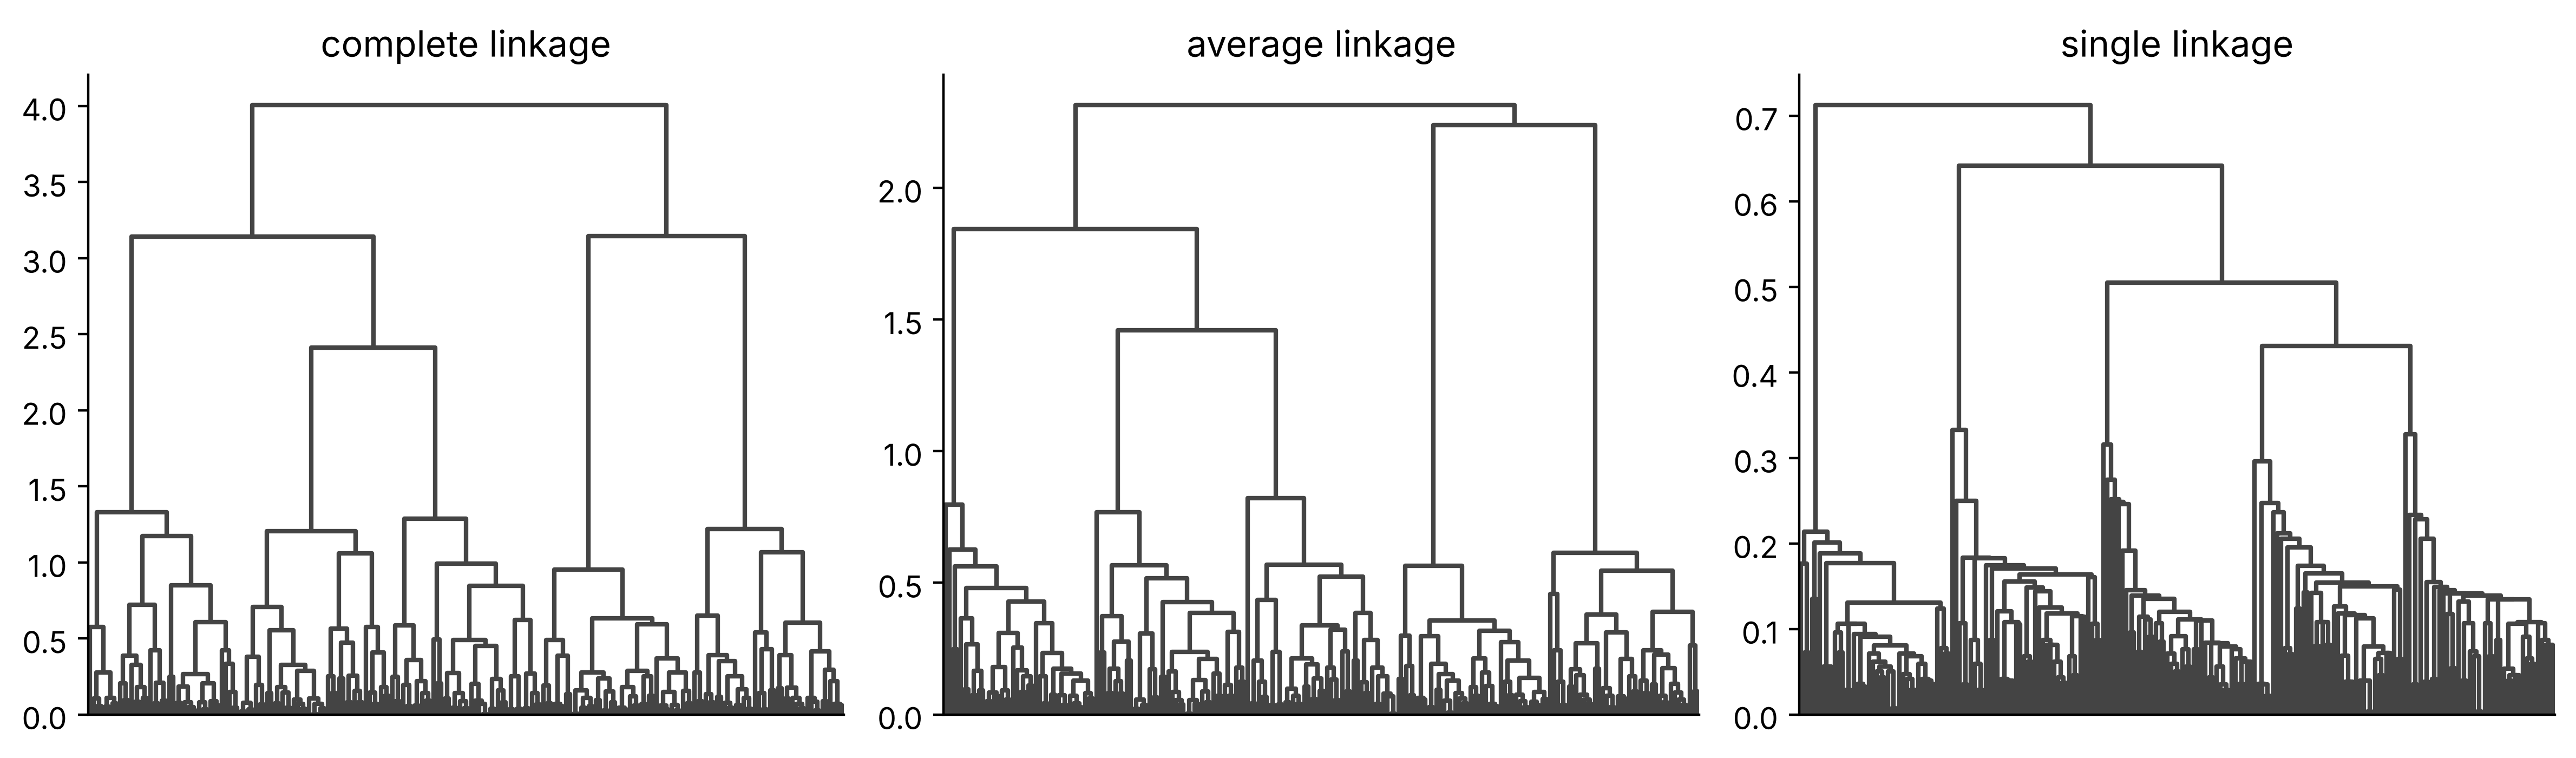

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, method in zip(axes, ["complete", "average", "single"]):
    dendrogram(linkage(X_scaled, method=method), ax=ax, no_labels=True, color_threshold=0, above_threshold_color="#444")
    ax.set_title(f"{method} linkage")
    ax.grid(False)
plt.tight_layout()
plt.show()

**Line by line**

1. `fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))`  
   Three panels side by side.
2. `for ax, method in zip(axes, ["complete", "average", "single"]):`  
   One linkage per panel.
3. `dendrogram(linkage(X_scaled, method=method), ax=ax, no_labels=True, color_threshold=0, above_threshold_color="#444")`  
   Build and draw the tree in plain grey.
4. `ax.set_title(f"{method} linkage")`  
   Name the panel.
5. `ax.grid(False)`  
   No grid.
6. `plt.tight_layout()`  
   Stop the titles overlapping.
7. `plt.show()`  
   Display.

## 12. Summary

| Step | Code |
|---|---|
| Scale | `StandardScaler().fit_transform(X)` |
| K-means | `KMeans(n_clusters=K, n_init=10).fit_predict(X_scaled)` |
| Choose K | elbow on `inertia_`; `silhouette_score` |
| Centroids in real units | `scaler.inverse_transform(kmeans.cluster_centers_)` |
| Tree | `linkage(X_scaled, method="ward")`, `dendrogram(Z)` |
| Cut the tree | `fcluster(Z, t=K, criterion="maxclust")` |

## 13. Exercises

1. Add `age` as a third clustering feature. Does the best K change?
2. Run the K-means cell **without** `StandardScaler`. Which feature dominates, and why?
3. Replace `"ward"` with `"single"` in the dendrogram and cut it into 5 clusters. Compare with K-means using the adjusted Rand index.
4. Give each of the five segments a marketing action. Which segment would you target first?